# Design Parameters to Control Synthetic Gene Expression in Escherichia coli

- https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0007002
- Codon optimization of two heterologous proteins in E. coli
- Absolute protein quantification and lots of strain variants

To Do:
- Revisit when parallelization is implemented

In [45]:
# packages
include("packages.jl")

🔧 Julia started with 8 threads


parameters (generic function with 1 method)

## Load data

In [6]:
# Sequences and expression from Welch_2009
df = readmatrix("../data/validation/welch_2009/Welch_2009.xlsx", "table1", "A1:C79"); # sequence and expression data from Welch 2009
seq_names_welch = string.(df[2:end,1]); # file names 
first(seq_names_welch, 3)

3-element Vector{String}:
 "A1"
 "A2"
 "A3"

In [7]:
# Sequences 
sequence_file	    = "Ecoli_K12_MG1655_geneset_with_welch_2009.fa"    # "lacS_background.fa"
hybrid_file		    = "lacS.txt"
seqs_to_use 	    = (1,2401)                                 # Range of sequences in Fasta file. Takes all sequences from sequence a to sequence b
num_background_genes = 12

# initialization of data containers
scale = txtl_types.init_scale()         # struct that makes it possible to influence rates by scaling them

µ = 1                    # A growth rate (0.1 to 1.8) can be chosen and the proteins of the TXTL machinery will be tuned according to that growth rate and the processivity of the RNA polymerase

## flags for efficiency factors
positive_aminoacid	= true 
anti_shinedalgarno	= false      # If no hybridization file is available put flag to false. We apply the intaRNA program's intarna function (q: aSD, t: sequence, SeedBP: 5, out: tMinE) to generate a hybridization profile along the sequence. Link to the website: https://rna.informatik.uni-freiburg.de/IntaRNA/Input.jsp;jsessionid=2AE257E91E7276283F22CD77A5A8AA03
dynamic_efficiency	= true 
save_data           = false

flags = txtl_types.flags(positive_aminoacid, anti_shinedalgarno, dynamic_efficiency)

# Data import --------
mRNA 		= to_DataFrame(readmatrix("../data/input/mRNA_concentrations.xlsx", "mRNA_concentration", "A1:B2402")) # mRNA_concentration_high_cell_v
mRNA.mRNA 	= Float64.(mRNA.mRNA);

background_genes = String.(first(mRNA.gene, num_background_genes));

## Solve ODEs

In [ ]:
for i in seq_names_welch

    # Gene of interest
    heterologous_genes  = [i]
    println(heterologous_genes)
    genes = vcat(background_genes, heterologous_genes)

    mRNA_welch = subset(mRNA, :gene => ByRow(in(genes)));

    solution, p_parallel 	= competition_model(genes, µ, sequence_file, hybrid_file, flags, seqs_to_use, mRNA_welch)

    # Save results 
    # Save params 
    filename = "welch_2009_tags_$heterologous_genes.jld2"
    save_object(filename,p_parallel)

    # Save solution
    filename = "welch_2009_solutions._$heterologous_genes.jld2"
    save_object(filename,solutions)

end

["A1"]

⏳ Integrating ODE system (threaded, 13 sequences)...
Integration completed!
["A2"]

⏳ Integrating ODE system (threaded, 13 sequences)...
Integration completed!
["A3"]

⏳ Integrating ODE system (threaded, 13 sequences)...
Integration completed!
["A4"]

⏳ Integrating ODE system (threaded, 13 sequences)...
Integration completed!
["A5"]

⏳ Integrating ODE system (threaded, 13 sequences)...
Integration completed!
["A6"]

⏳ Integrating ODE system (threaded, 13 sequences)...
Integration completed!
["A7"]

⏳ Integrating ODE system (threaded, 13 sequences)...
Integration completed!
["A8"]

⏳ Integrating ODE system (threaded, 13 sequences)...
Integration completed!
["A9"]

⏳ Integrating ODE system (threaded, 13 sequences)...
Integration completed!
["A10"]

⏳ Integrating ODE system (threaded, 13 sequences)...
Integration completed!
["A11"]

⏳ Integrating ODE system (threaded, 13 sequences)...
Integration completed!
["A12"]

⏳ Integrating ODE system (threaded, 13 sequences)...
Integration 

## Load data

In [19]:
df = readmatrix("../data/validation/welch_2009/Welch_2009.xlsx", "table1", "A1:C79"); # sequence and expression data from Welch 2009

In [29]:
solutions_list = jldopen("welch_2009_solutions.jld2", "r")
tags_list = jldopen("welch_2009_tags.jld2", "r")

sol = solutions_list["single_stored_object"][1]
local_tags_list = tags_list["single_stored_object"][1]



13-element Vector{Main.txtl_types.data_struct_integration}:
 Main.txtl_types.data_struct_integration(Main.txtl_types.scale(1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0], 0.0, 0.0), Main.txtl_types.indices_dynamic_variables(1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137), Main.txtl_types.species_and_sequences(["lpp", "rplE", "rplU", "rpmJ", "tufA", "fusA", "ompF", "tufB", "a

## Organize solution data

In [30]:
df_list = sequence_dataframes(sol, local_tags_list); # Divide sequences in a list of dataframes that have the metabolites for all and the ribosomes for one sequence
sequences = Dict(x => i for (i, x) in enumerate(local_tags_list[1].seq_names)) # Dictionary that connects the index with the name of a sequence in local_tags_list
println("Sequences in data set:")
for i in eachindex(local_tags_list[1].seq_names)
    println(local_tags_list[1].seq_names[i])
end

Sequences in data set:
lpp
rplE
rplU
rpmJ
tufA
fusA
ompF
tufB
acpP
rpsK
gapA
rpsL
A1


## Calculate translation rates

In [ ]:
sequence_name    = local_tags_list[1].seq_names[end]
idx         = sequences[sequence_name]

translation_rate = calculate_translation_rate(df_list[idx])

0.192781643741675

In [41]:
# Calculate all translation rates 
translation_rates = []
sequence_names = []

for i in 1:76
    sol = solutions_list["single_stored_object"][i]
    local_tags_list = tags_list["single_stored_object"][i]
    df_list = sequence_dataframes(sol, local_tags_list); # Divide sequences in a list of dataframes that have the metabolites for all and the ribosomes for one sequence
    sequences = Dict(x => i for (i, x) in enumerate(local_tags_list[1].seq_names)) # Dictionary that connects the index with the name of a sequence in local_tags_list
    sequence_name    = local_tags_list[1].seq_names[end]
    idx         = sequences[sequence_name]
    translation_rate = calculate_translation_rate(df_list[idx])

    push!(translation_rates, translation_rate)
    push!(sequence_names, sequence_name)
end
 

translation_rates

76-element Vector{Any}:
 0.192781643741675
 0.19278165416364254
 0.19278164707490408
 0.19278165289600854
 0.19278164824909683
 0.19278164494479189
 0.19278164412923351
 0.19278165450807114
 0.19278164558014516
 0.19278164820680715
 0.19278164419863364
 0.1927816580122291
 0.1927816552927892
 ⋮
 0.19278174606852275
 0.19278174444328355
 0.19278173932617873
 0.1927817513373271
 0.19278174616562113
 0.19278174455969133
 0.192781746839778
 0.1927817583029008
 0.19278176128171204
 0.19278176025816604
 0.19278176086917626
 0.1927817599457512

## Calculate absolute protein concentrations

- Incubation for 4 hours
- no µ given - we assume 1
- starting OD? - Induction of expression when cells were in mid-log growth with OD = 0.6

In [46]:
# Parameters
OD 			= 0.6
c_x0	 	= OD * 0.3 # g/L
µ 			= 1
t_process	= 4			# h

# parameters to calculate qp 
weight_cell	= 6e-13		# weight of a cell 
volume_cell = 4e-16		# L

# Antibody
mass_protein = 25412 	# Da -> g/mol						Calculated in file molar_mass_for_proteins.ipynb
v_t_antibody = translation_rates[1:42]
c_A = calculate_absolute_protein_µgmL.(c_x0, µ, t_process, weight_cell, volume_cell, v_t_antibody, mass_protein) # µg/mL

# # Polymerase 
# mass_protein	= 56244		# Da -> g/mol						Calculated in file molar_mass_for_proteins.ipynb
# v_t_polymerase	= translation_rates[43:end]
# c_P 	= calculate_absolute_protein_µgmL.(c_x0, µ, t_process, weight_cell, volume_cell, v_t_polymerase, mass_protein); # µg/mL



42-element Vector{Float64}:
 1890.5441420311286
 1890.544244235827
 1890.5441747189752
 1890.5442318045707
 1890.5441862338848
 1890.544153829688
 1890.5441458317835
 1890.5442476135215
 1890.544160060382
 1890.5441858191643
 1890.5441465123672
 1890.5442819776088
 1890.5442553089856
    ⋮
 1890.54412281559
 1890.544131005567
 1890.544157563069
 1890.5441579761002
 1890.544232434245
 1890.5441451019353
 1890.5441712751012
 1890.544137799409
 1890.544145385717
 1890.544210994842
 1890.5441865210057
 1890.5441594531887

In [47]:
headers = df[1, 1:2]
data	= df[2:43,1:2]
df_A 	= DataFrame(data, headers)
df_A.predictions = c_A

# data 	= df[44:end,1:2]
# df_P 	= DataFrame(data, headers)
# df_P.predictions = c_P;

42-element Vector{Float64}:
 1890.5441420311286
 1890.544244235827
 1890.5441747189752
 1890.5442318045707
 1890.5441862338848
 1890.544153829688
 1890.5441458317835
 1890.5442476135215
 1890.544160060382
 1890.5441858191643
 1890.5441465123672
 1890.5442819776088
 1890.5442553089856
    ⋮
 1890.54412281559
 1890.544131005567
 1890.544157563069
 1890.5441579761002
 1890.544232434245
 1890.5441451019353
 1890.5441712751012
 1890.544137799409
 1890.544145385717
 1890.544210994842
 1890.5441865210057
 1890.5441594531887

## Smoothed elongation profiles

In [10]:
# packages
include("01_packages.jl")
using JLD2

data = load("welch_2009_tags.jld2")
tags_list_all = data["single_stored_object"];

data = load("welch_2009_solutions.jld2")
solutions_all = data["single_stored_object"];

using Plots 
using Measures

default(
	linewidth 	= 3,
	guidefont 	= font(26),
	tickfont 	= font(18),
	titlefont	= font(18)

	)

### Single chain antibody

In [11]:
tags_list = tags_list_all[1:42]
solutions = solutions_all[1:42]


# efficiency factors
V_TL_EL_list         = []
efficiencies_list    = []
pos_amino_list       = []
dyn_efac_list        = []

y_rib_list           = []

V_EL_smooth_list     = []
h1_list              = []
V_ELO_list           = []

for i in 1:length(tags_list)

    sol     = solutions[i]
    tags    = tags_list[i]

    # efficiency factors
    V_TL_EL, efficiencies, pos_amino, dyn_efac = four_V_TL_EL(sol[end], tags)
    y_rib = sol[end][139:end]
    push!(V_TL_EL_list, V_TL_EL)
    push!(efficiencies_list, efficiencies)
    push!(pos_amino_list, pos_amino)
    push!(dyn_efac_list, dyn_efac)

    # ribosome concentrations
    push!(y_rib_list, y_rib)

    # V_TL_EL divided by ribosome concentration and smoothed with sliding window
    V_EL_smooth, h1, V_ELO = V_EL_smooth_analyze_parallel_data(tags, V_TL_EL, y_rib)
    push!(V_EL_smooth_list, V_EL_smooth)
    push!(h1_list, h1)
    push!(V_ELO_list, V_ELO)

end

average_antibody = mean.(h1_list)
df_A.mean_v_elo  = average_antibody;

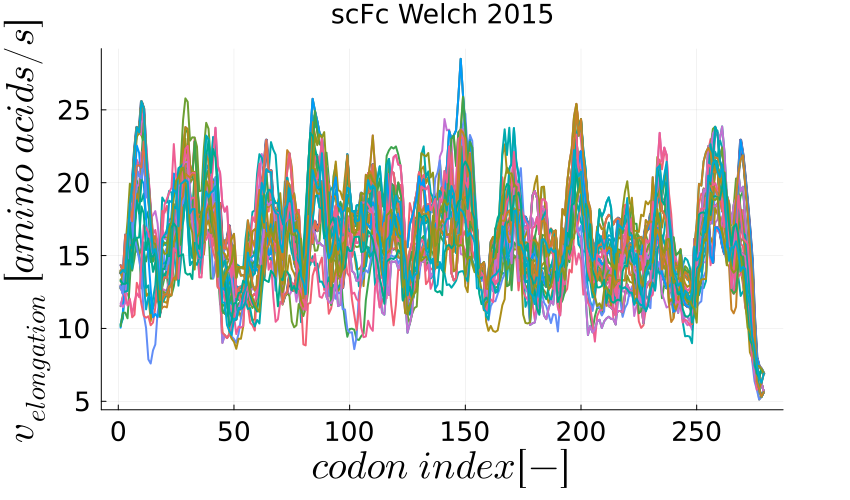

In [12]:
plt = plot(V_EL_smooth_list[1], xlabel = L"codon\ index [-]", 
	ylabel = L"v_{elongation}\ [amino\ acids/s]", label = "BSLA WT",
	size = (850, 500), left_margin = 5mm, bottom_margin = 7mm, top_margin = 5mm, right_margin = 15mm,
	legend=false, legendfontsize = 18, linecolor = farben.marine, title = "scFc Welch 2015")

	for (idx, codon) in enumerate(c_A)
		plot!(plt, V_EL_smooth_list[idx], linewidth = 2)
	end

	plot!(plt, legendfont = font(12), legend = false)

	display(plt)

### Polymerase

In [13]:
tags_list = tags_list_all[43:end]
solutions = solutions_all[43:end]


# efficiency factors
V_TL_EL_list         = []
efficiencies_list    = []
pos_amino_list       = []
dyn_efac_list        = []

y_rib_list           = []

V_EL_smooth_list     = []
h1_list              = []
V_ELO_list           = []

for i in 1:length(tags_list)

    sol     = solutions[i]
    tags    = tags_list[i]

    # efficiency factors
    V_TL_EL, efficiencies, pos_amino, dyn_efac = four_V_TL_EL(sol[end], tags)
    y_rib = sol[end][139:end]
    push!(V_TL_EL_list, V_TL_EL)
    push!(efficiencies_list, efficiencies)
    push!(pos_amino_list, pos_amino)
    push!(dyn_efac_list, dyn_efac)

    # ribosome concentrations
    push!(y_rib_list, y_rib)

    # V_TL_EL divided by ribosome concentration and smoothed with sliding window
    V_EL_smooth, h1, V_ELO = V_EL_smooth_analyze_parallel_data(tags, V_TL_EL, y_rib)
    push!(V_EL_smooth_list, V_EL_smooth)
    push!(h1_list, h1)
    push!(V_ELO_list, V_ELO)

end

average_polymerase = mean.(h1_list)
df_P.mean_v_elo  = average_polymerase;

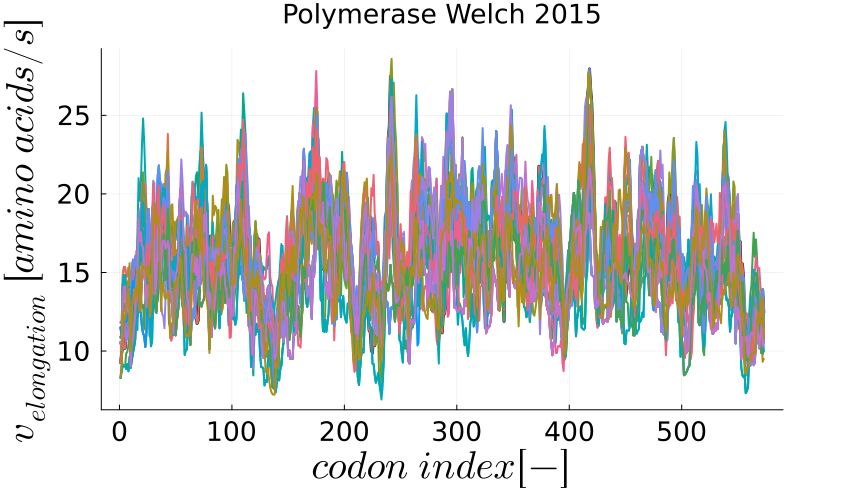

In [14]:
plt = plot(V_EL_smooth_list[1], xlabel = L"codon\ index [-]", 
	ylabel = L"v_{elongation}\ [amino\ acids/s]", label = "BSLA WT",
	size = (850, 500), left_margin = 5mm, bottom_margin = 7mm, top_margin = 5mm, right_margin = 15mm,
	legend=false, legendfontsize = 18, linecolor = farben.marine, title = "Polymerase Welch 2015")

	for (idx, codon) in enumerate(c_P)
		plot!(plt, V_EL_smooth_list[idx], linewidth = 2)
	end

	plot!(plt, legendfont = font(12), legend = false)

	display(plt)

## Rank comparison

In [54]:
df_A = subset(df_A, :expression .=> ByRow(x -> x != "nd"), skipmissing=false)
# df_P = subset(df_P, :expression .=> ByRow(x -> x != "nd"), skipmissing=false);

using StatsBase
using Statistics
df_A.expression_rank = ordinalrank(df_A.expression)
df_A.prediction_rank = ordinalrank(df_A.predictions)
# df_A.v_elo_rank 	 = ordinalrank(df_A.mean_v_elo)

rho = cor(df_A.expression_rank, df_A.prediction_rank)

# df_P.expression_rank = ordinalrank(df_P.expression)
# df_P.prediction_rank = ordinalrank(df_P.predictions);
# df_P.v_elo_rank 	 = ordinalrank(df_P.mean_v_elo);

-0.21077712609970675

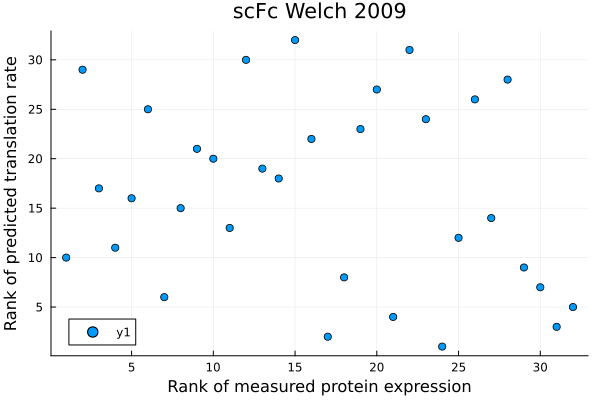

In [56]:

# plot 
scatter(df_A.expression_rank,df_A.prediction_rank,
xlabel = "Rank of measured protein expression",
ylabel = "Rank of predicted translation rate",
title = "scFc Welch 2009")


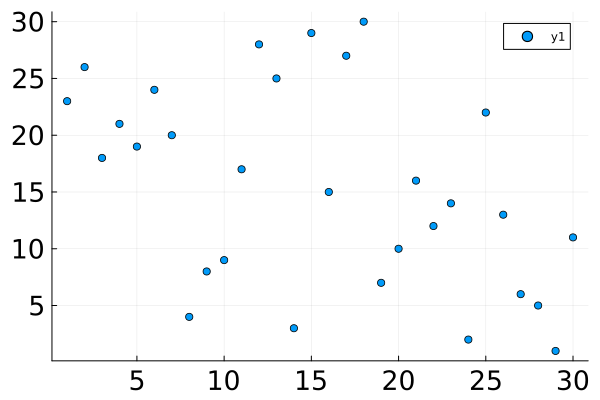

In [17]:
scatter(df_P.expression_rank,df_P.v_elo_rank)